In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal

In [5]:
df = pd.read_csv("emg_data.csv")

# tiempo relativo (más fácil de interpretar)
df["timestamp"] = df["timestamp"] - df["timestamp"].iloc[0]
df["emg_smooth"] = df["emg"].rolling(250).mean()
df["emg_smooth"] -= df["emg_smooth"].min()

df["y_smooth"] = df["y"].rolling(250).mean()
df["y_smooth"] -= df["y_smooth"].max()
df["y_smooth"] *= -0.01

print(len(df))
df.head()

15691


,t_micros,x,y,emgd,emg_smooth,y_smooth
0,8,520,507,536,NaN,NaN
1,1076,520,507,534,NaN,NaN
2,2224,520,507,529,NaN,NaN
3,3368,520,507,525,NaN,NaN
4,4512,520,507,521,NaN,NaN


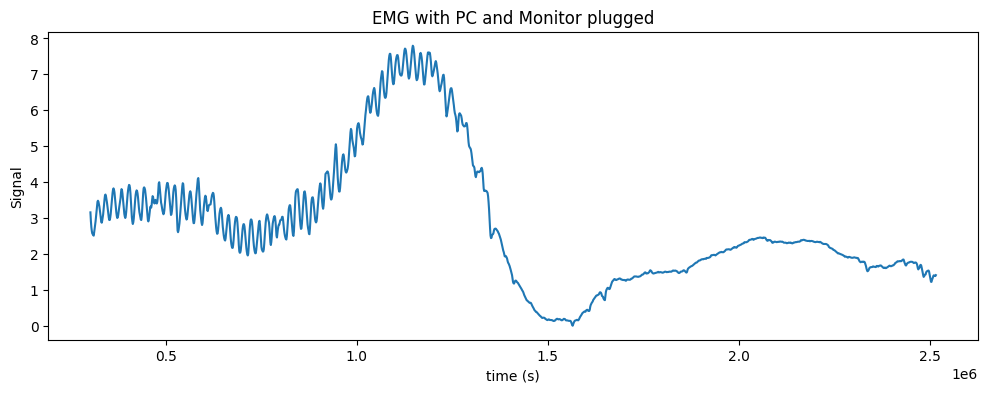

In [6]:
def plot_signal(t, signal, title):
    plt.figure(figsize=(12,4))
    plt.plot(t, signal)
    plt.xlabel("time (s)")
    plt.ylabel("Signal")
    plt.title(title)
    plt.show()    

def plot_emg_vs_joystick(t, emg, y):
    plt.figure(figsize=(12,4))
    plt.plot(t, emg)
    plt.plot(t, y)
    plt.xlabel("time (s)")
    plt.title("Smoothed EMG")
    plt.show()

def plot_frequencies(signal, fs, center=False, title=""):
    if center:
        signal = signal - np.mean(signal)

    N = len(signal)

    fft_vals = np.fft.rfft(signal)
    freqs = np.fft.rfftfreq(N, 1/fs)
    
    magnitude = np.abs(fft_vals)
    
    plt.figure(figsize=(10,5))
    plt.plot(freqs, magnitude)
    
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    if title:
        plt.title(title)
    else:
        plt.title("Signal Frequency Spectrum")
    
    plt.xlim(0, 400)
    plt.grid()
    
    plt.show()
    
plot_signal(df["t)"][20:2000], df["emg_smooth"][20:2000], "EMG with PC and Monitor plugged")

In [11]:
# La señal es ruidosa, vamos a ver cual es la frecuencia correspondiente haciendo análisis de fourier para entender 
# cual es la fuente del ruido
t = df["t_micros"].values * 1e-6
dt = np.diff(t)
fs = 1 / np.mean(dt)
print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

Sampling frequency: 764.6552092172678 Hz
Sampling Standard Deviation: 3.5368861600151106e-05 Hz


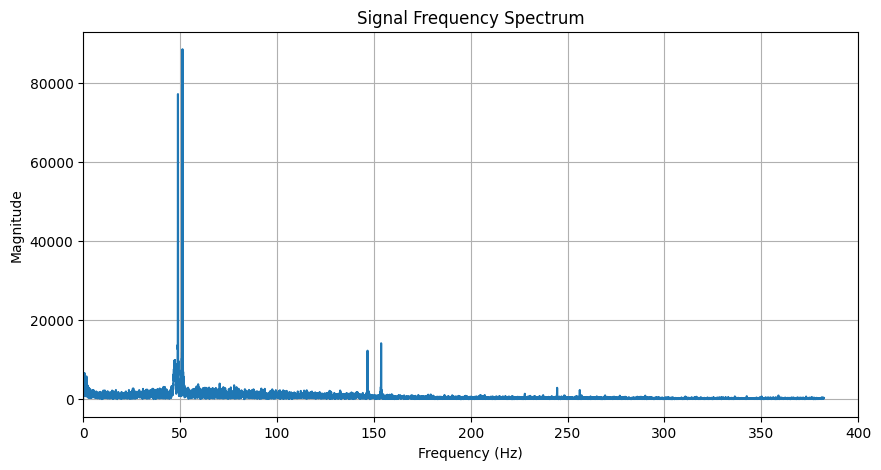

In [16]:
emg = df["emgd"].values
plot_frequencies(emg, fs, center=True)

In [13]:
df["emg_smooth"].corr(df["y_smooth"])

np.float64(-0.009276457629489613)

In [14]:
plot_emg_vs_joystick(df["timestamp"], df["emg_smooth"], df["y_smooth"])

KeyError: 'timestamp'

In [15]:
df = pd.read_csv("emg_data_unplugged.csv")

# tiempo relativo (más fácil de interpretar)
df["timestamp"] = df["timestamp"] - df["timestamp"].iloc[0]
df["emg_smooth"] = df["emg"].rolling(250).mean()
df["emg_smooth"] -= df["emg_smooth"].min()

df["y_smooth"] = df["y"].rolling(250).mean()
df["y_smooth"] -= df["y_smooth"].max()
df["y_smooth"] *= -0.01


plot_signal(df["timestamp"][20:2000], df["emg_smooth"][20:2000], "EMG with PC and Monitor UNPLUGGED")

FileNotFoundError: [Errno 2] No such file or directory: 'emg_data_unplugged.csv'

Sampling frequency: 825.7473897814122 Hz
Sampling Standard Deviation: 0.0011585773265211604 Hz


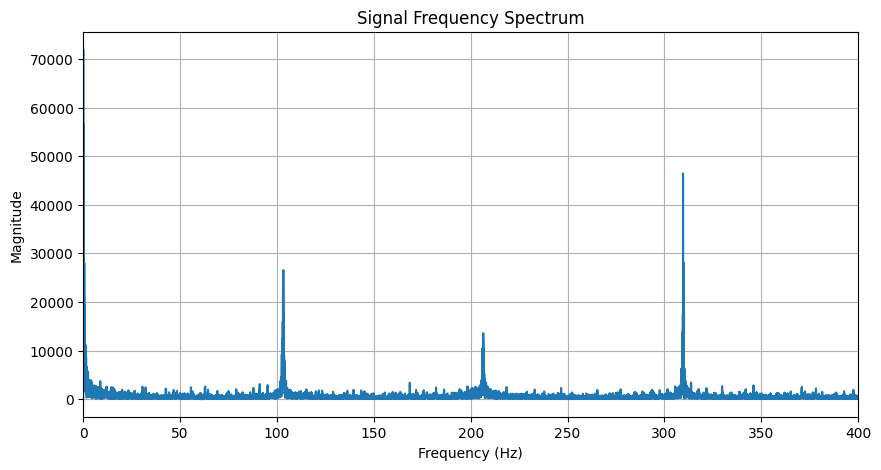

In [130]:
dt = np.diff(df["timestamp"])
fs = 1 / np.mean(dt)

print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

emg = df["emg"].values
plot_frequencies(emg, fs, center=True)

The noise at 50hz comming from the electrical networks dissappeared but we still have some spikes at 105, 210 and 315

0.9718940433294024


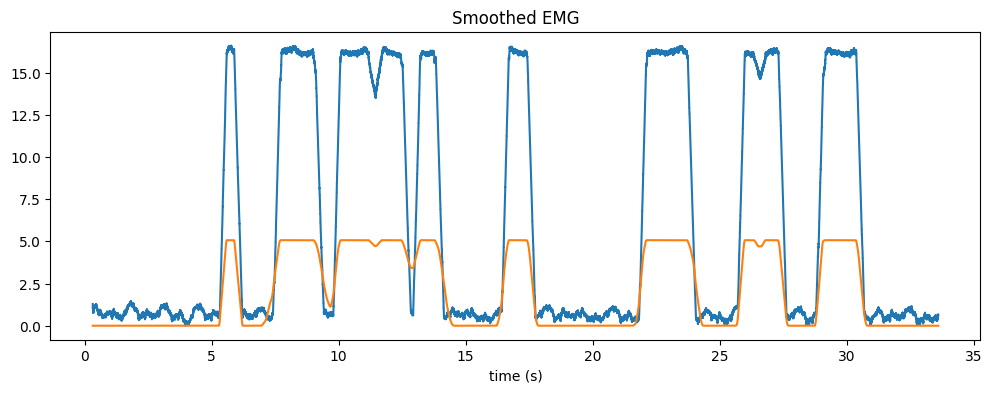

In [131]:
print(df["emg_smooth"].corr(df["y_smooth"]))
plot_emg_vs_joystick(df["timestamp"], df["emg_smooth"], df["y_smooth"])

Let's apply some notch filters to understand if the spikes we see in the freq domain is noise or is the signal itself

In [155]:
def apply_notch_filter(emg, f0, Q, fs):
    b_notch, a_notch = signal.iirnotch(f0, Q, fs)
    return signal.filtfilt(b_notch, a_notch, emg)

In [20]:
# Apply notch filters to remove that noise
emg = df["emg"]
emg = emg - emg.min()


def apply_notch_filter(emg, f0, Q, fs):
    b_notch, a_notch = signal.iirnotch(f0, Q, fs)
    return signal.filtfilt(b_notch, a_notch, emg)
    
emg = apply_notch_filter(emg, 310, 30, fs)
emg = apply_notch_filter(emg, 207, 30, fs)
emg = apply_notch_filter(emg, 103, 30, fs)

df["emg_notched"] = emg
print(df["emg_notched"].corr(df["y_smooth"]))
plot_frequencies(df["emg_notched"], fs, center=False)

KeyError: 'emg'

The correlation coeff got significantly lower so those frequencies are not purely noise, they carry information. Let's try just with
a simple low pass to see if it doesn't get worse.

In [19]:
b_env, a_env = signal.butter(1, 1, btype="low", fs=fs)
emg_env = signal.filtfilt(b_env, a_env, df["emg"])
df["emg_env"] = emg_env - emg_env.min()

print(df["emg_env"].corr(df["y_smooth"]))
plot_emg_vs_joystick(df["timestamp"], df["emg_env"], df["y_smooth"])

KeyError: 'emg'

The correlation got a little bit smaller but the signal smoother and it clearly anticipates 
the movement of the joystick in direction and amplitude which is great for trainning a Neural Network for control 

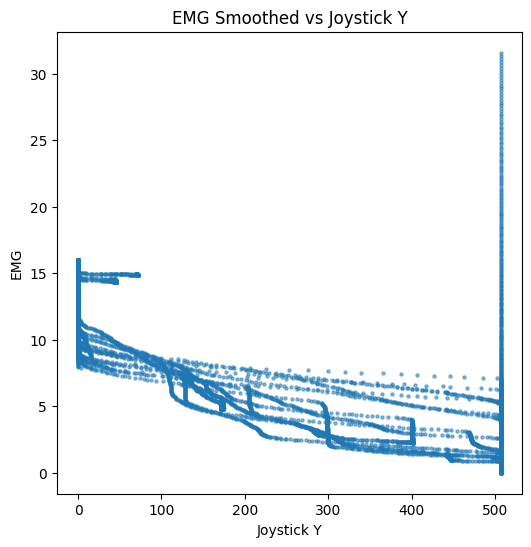

In [217]:
plt.figure(figsize=(6,6))
plt.scatter(df["y"], df["emg_env"], s=5, alpha=0.5)
plt.xlabel("Joystick Y")
plt.ylabel("EMG")
plt.title("EMG Smoothed vs Joystick Y")
plt.show()